# an0065@uah.edu
# https://github.com/zippermergegh/zippermerge

# 1. Automatic Differentiation and Expression Graph

In [7]:
# Inputs
w, x, y, z = 1, 2, 3, 4

# Forward pass (node by node)
a = w * x
b = y ** 2
c = b * z
f = a + c

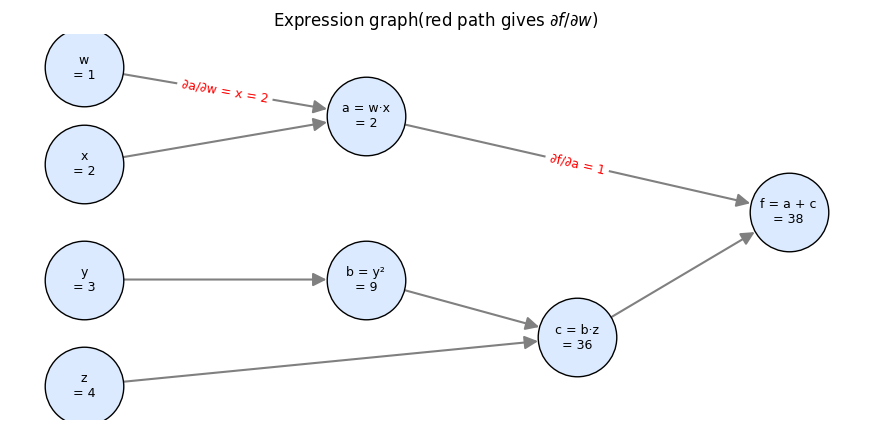

In [8]:
import matplotlib.pyplot as plt
import networkx as nx

G = nx.DiGraph()
edges = [("w", "a"), ("x", "a"), ("y", "b"), ("b", "c"),
         ("z", "c"), ("a", "f"), ("c", "f")]
G.add_edges_from(edges)

pos = {"w": (0, 3), "x": (0, 2), "y": (0, 0.8), "z": (0, -0.3),
       "a": (2, 2.5), "b": (2, 0.8), "c": (3.5, 0.2), "f": (5, 1.5)}

labels = {
    "w": f"w\n= {w}", "x": f"x\n= {x}", "y": f"y\n= {y}", "z": f"z\n= {z}",
    "a": f"a = w·x\n= {a}", "b": f"b = y²\n= {b}",
    "c": f"c = b·z\n= {c}", "f": f"f = a + c\n= {f}",
}

path_edges = [("w", "a"), ("a", "f")]
edge_colors = ["gray" for e in G.edges()]
edge_widths = [1.5 for e in G.edges()]

fig, ax = plt.subplots(figsize=(11, 5))
nx.draw_networkx_nodes(G, pos, node_size=3200, node_color="#dbeafe",
                       edgecolors="black", ax=ax)
nx.draw_networkx_edges(G, pos, edge_color=edge_colors, width=edge_widths,
                       arrows=True, arrowsize=20, node_size=3200, ax=ax)
nx.draw_networkx_labels(G, pos, labels, font_size=9, ax=ax)

# Local gradients on the path
nx.draw_networkx_edge_labels(
    G, pos, edge_labels={("w", "a"): f"∂a/∂w = x = {x}",
                         ("a", "f"): "∂f/∂a = 1"},
    font_color="red", font_size=9, ax=ax)

ax.set_title(r"Expression graph"
             r"(red path gives $\partial f/\partial w$)")
ax.axis("off")
plt.show()

In [9]:
# Local derivatives along the path w -> a -> f
df_da = 1
da_dw = x

df_dw = df_da * da_dw
print(f"∂f/∂a = {df_da}")
print(f"∂a/∂w = {da_dw}")
print(f"∂f/∂w = {df_da} * {da_dw} = {df_dw}")

∂f/∂a = 1
∂a/∂w = 2
∂f/∂w = 1 * 2 = 2


# 2. Unconstrained Optimization

# Problem 1

$$f(x) = x^2 - 4x + 4$$

**Critical Point:**
$$f'(x) = 2x - 4$$

$$2x - 4 = 0 \;\Rightarrow\; x = 2$$

$$f''(x) = 2 > 0$$
Since $f''(2) > 0$, $x = 2$ is a minimum.

**Minimum Value:**
$$f(2) = 2^2 - 4(2) + 4 = 0$$

Critical point is $x = 2$ and the minimum value is $0$.

# Problem 2

$$f(x) = x^3 - 3x^2$$

**Critical Points:**
$$f'(x) = 3x^2 - 6x = 3x(x - 2)$$

$$3x(x-2) = 0 \;\Rightarrow\; x = 0 \text{ or } x = 2$$

$$f''(x) = 6x - 6$$

**Local minimum $x=0$**: $$f''(0) = -6 < 0$$
**Local maximum $x=2$**: $$f''(2) = 6 > 0$$

**Values:**
$$f(0) = 0^3 - 3(0)^2 = 0$$
$$f(2) = 2^3 - 3(2)^2 = 8 - 12 = -4$$

Critical points: $x = 0$ and $x = 2$

Local maximum at $x = 0$, with value $f(0) = 0$

Local minimum at $x = 2$, with value $f(2) = -4$

# Problem 3

$$f(x, y) = x^2 - y^2$$

**Gradient:**
$$\nabla f = \left( \frac{\partial f}{\partial x}, \frac{\partial f}{\partial y} \right) = (2x, \; -2y)$$

**Critical point:**
$$2x = 0, \quad -2y = 0 \;\Rightarrow\; (x, y) = (0, 0)$$

**Classify using Hessian:**
$$H = \begin{bmatrix} f_{xx} & f_{xy} \\ f_{yx} & f_{yy} \end{bmatrix}
= \begin{bmatrix} 2 & 0 \\ 0 & -2 \end{bmatrix}$$

$$\det(H) = (2)(-2) - (0)(0) = -4 < 0$$

Since $\det(H) < 0$, Hessian has one positive and one negative eigenvalue, so the point is a saddle point.

# 3. Constrained Optimization using Lagrange Multiplier

## 1. Set up the Lagrangian

$$\mathcal{L}(x,y,z,\lambda) = x^2 + y^2 + z^2 - \lambda\,(x + 2y + z - 6)$$

## 2. Derive the system of equations

$$\frac{\partial \mathcal{L}}{\partial x} = 2x - \lambda = 0 $$
$$\frac{\partial \mathcal{L}}{\partial y} = 2y - 2\lambda = 0 $$
$$\frac{\partial \mathcal{L}}{\partial z} = 2z - \lambda = 0 $$
$$\frac{\partial \mathcal{L}}{\partial \lambda} = -(x + 2y + z - 6) = 0 $$

## 3. Solve for critical points

$$x = \frac{\lambda}{2}, \qquad y = \lambda, \qquad z = \frac{\lambda}{2}$$

Substitute:
$$\frac{\lambda}{2} + 2\lambda + \frac{\lambda}{2} = 6 \;\Rightarrow\; 3\lambda = 6 \;\Rightarrow\; \lambda = 2$$

Therefore:
$$x = 1, \qquad y = 2, \qquad z = 1$$

**Critical Point:** $(x,y,z) = (1, 2, 1)$ with $\lambda = 2$.

**Function Value:**
$$1^2 + 2^2 + 1^2 = 6$$

## 4. Classify extrema

**Hessian:**
$$H = \begin{bmatrix} 2 & 0 & 0 \\ 0 & 2 & 0 \\ 0 & 0 & 2 \end{bmatrix}$$

All eigenvalues equal $2 > 0$. Therefore, it is positive definite. $(1, 2, 1)$ is the global minimum, with $f_{\min} = 6$.

## 5. Role of the constraint

Without the constraint, the minimum of $f$ is at the origin, so the constraint forces the optimization onto the plane $x + 2y + z = 6$, which does not contain the origin. It also reduces the dimension, since the problem goes from 3 variables to 2 variables.


# 4. Optimizating a Function using Stochastic Gradient Descent

## Gradient

$$\frac{dJ}{dw_1} = 4(w_1 - 5)^3 + 2(w_1 - 3)$$

**Update rule:**
$$w_1^{(t+1)} = w_1^{(t)} - \eta \, \frac{dJ}{dw_1}\bigg|_{w_1^{(t)}}$$

## Iterations

**Iteration 1** ($w_1^{(0)} = 2$)
$$J'(2) = 4(-3)^3 + 2(-1) = -108 - 2 = -110$$
$$w_1^{(1)} = 2 - 0.1(-110) = \mathbf{13}$$

**Iteration 2** ($w_1^{(1)} = 13$)
$$J'(13) = 4(8)^3 + 2(10) = 2048 + 20 = 2068$$
$$w_1^{(2)} = 13 - 0.1(2068) = \mathbf{-193.8}$$

**Iteration 3** ($w_1^{(2)} = -193.8$)
$$J'(-193.8) = 4(-198.8)^3 + 2(-196.8) = -3.1428 \times 10^{7}$$
$$w_1^{(3)} = -193.8 + 0.1(3.1428 \times 10^{7}) = \mathbf{3.1426 \times 10^{6}}$$

**Iteration 4** ($w_1^{(3)} = 3.1426 \times 10^{6}$)
$$J'(w_1^{(3)}) = 4(3.1426 \times 10^{6})^3 = 1.2414 \times 10^{20}$$
$$w_1^{(4)} = 3.1426 \times 10^{6} - 1.2414 \times 10^{19} = \mathbf{-1.2414 \times 10^{19}}$$

**Iteration 5** ($w_1^{(4)} = -1.2414 \times 10^{19}$)
$$J'(w_1^{(4)}) = 4(-1.2414 \times 10^{19})^3 = -7.653 \times 10^{57}$$
$$w_1^{(5)} = -1.2414 \times 10^{19} + 7.653 \times 10^{56} = \mathbf{7.65 \times 10^{56}}$$

## Comparison with the partial differentiation method

$$4(w_1 - 5)^3 + 2(w_1 - 3) = 0$$

Let $u = w_1 - 5$, so $w_1 - 3 = u + 2$:
$$4u^3 + 2(u + 2) = 0 \;\Rightarrow\; 2u^3 + u + 2 = 0$$

Derivative of $2u^3 + u + 2$ is $6u^2 + 1 > 0$, so the cubic is strictly increasing and has one real root.
$$u = -0.835 \;\Rightarrow\; w_1 = 4.165$$

**Classification:**
$$J''(w_1) = 12(w_1 - 5)^2 + 2 \ge 2 > 0 $$
$w_1$ is the global minimum.

**Minimum Value:**
$$J(w_1) = (-0.835)^4 + (1.165)^2 + 4 = 0.486 + 1.357 + 4 = 5.84$$

The analytical method gives the true minima at $w_1 = 4.165$. Gradient descent can reach the same point, but only with the right learning rate, which should liekly be smaller due to the overshooting values that seem to diverge rather than converge.

# 5. Linear Regression and Regularization

Using $\|v\|^2 = v^\top v$:

$$J(w) = (y - Xw)^\top (y - Xw) + \lambda w^\top w$$

$$J(w) = y^\top y - 2\,w^\top X^\top y + w^\top X^\top X\,w + \lambda\,w^\top w$$

## Gradient With Respect to $w$

Using the identities $\nabla(w^\top b) = b$ and $\nabla(w^\top Aw) = 2Aw$:

$$\nabla J = -2\,X^\top y + 2\,X^\top X\,w + 2\lambda\,w$$

## Solve Gradient

$$-2\,X^\top y + 2\,X^\top X\,w + 2\lambda\,w = \mathbf{0}$$

$$(X^\top X + \lambda I)\,w = X^\top y$$

$${\hat{w}_{\text{ridge}} = (X^\top X + \lambda I)^{-1} X^\top y}$$

The Hessian is
$$\nabla^2 J = 2(X^\top X + \lambda I)$$
$X^\top X$ is positive semi-definite, so for $\lambda > 0$ the matrix $X^\top X + \lambda I$ is positive definite. Therefore this is the global minimimum.

## Comparison with original linear regression

Setting $\lambda = 0$:

$$\hat{w}_{\text{OLR}} = (X^\top X)^{-1} X^\top y$$

The only difference is the $\lambda I$ term added to $X^\top X$.

## Impact of the penalty

Larger $\lambda$ penalizes large weights more heavily, pulling $\hat{w}$ values toward zero. In addition, the penalty acts as a bias, which reduces variance so predictions are less sensitive to noise in the training data. The result brings lower test error, with less overfitting.

# 6. Assumptions in Linear Regression

Linearity: The relationship between $x$ and the mean of $y$ is linear

Independence of Errors: The errors are independent of each other, meaning there is no autocorrelation

Homoscedasticity or Constant Variance: The error variance is the same for all values of x

Zero-mean errors: The errors average out to zero

Normality of errors: The errors follow a normal distribution

No Endogeneity: The predictor is uncorrelated with the error

# 7. Computing Derivative using PyTorch Autograd

In [10]:
import torch

def tau_fn(r, rs):
    return 2 * r * torch.sqrt(r / rs) * torch.sqrt(1 - rs / r)

r2  = torch.tensor(30000.1, dtype=torch.float64, requires_grad=True)
rs2 = torch.tensor(0.00887, dtype=torch.float64)

dtau_dr, = torch.autograd.grad(tau_fn(r2, rs2), r2)
print(f"d(tau)/dr = {dtau_dr.item():.6f}")

d(tau)/dr = 5517.226005


# 8. Linear Regression in One Variable with Scikit-Learn

In [11]:
import pandas as pd

url = ("https://raw.githubusercontent.com/rahulbhadani/Datasets/master/"
       "RAV4/2020-04-15-05-12-00_2T3Y1RFV8KC014025_CAN_Messages_5_Hz.csv")

df = pd.read_csv(url)

print(df.shape)
df[["steer_angle", "yaw_rate"]].head()

(8875, 16)


,steer_angle,yaw_rate
0,0.0,-0.072
1,0.0,-0.072
2,0.0,-0.316
3,0.0,-0.316
4,0.0,-0.316


In [12]:
from sklearn.model_selection import train_test_split

X = df[["steer_angle"]]   # independent variable (2D for scikit-learn)
y = df["yaw_rate"]        # response variable

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print(f"Train rows: {len(X_train)}, Test rows: {len(X_test)}")

Train rows: 6656, Test rows: 2219


In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(f"Coefficient (slope) : {model.coef_[0]:.6f}")
print(f"Intercept           : {model.intercept_:.6f}")
print(f"R^2 on test data    : {r2_score(y_test, y_pred):.4f}")

Coefficient (slope) : 0.066208
Intercept           : -0.207197
R^2 on test data    : 0.6556


# 9. Linear Regression in One Variable with PyTorch

In [14]:
!pip install zippermerge==0.4.1

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\anjan\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split
from zippermerge import LinearRegression

url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Hydropower.csv"
df = pd.read_csv(url)

print(df.shape)
df[["BCR", "AnnualProduction"]].head()

(191, 9)


,BCR,AnnualProduction
0,0.02,126
1,0.90,3218
2,0.35,546
3,0.49,1319
4,0.15,238


In [16]:
x = df["BCR"]
y = df["AnnualProduction"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=42
)
print(f"Train: {len(x_train)} rows, Test: {len(x_test)} rows")

Train: 143 rows, Test: 48 rows


In [17]:
model = LinearRegression(learning_rate=0.1, epochs=1000)
model.fit(x_train, y_train, x_test, y_test)

Learned parameters: w0 = -3035.7601, w1 = 11465.1049
R^2 on test data: 0.4620


0.4620411666860751

In [18]:
new_bcr = [0.5, 1.0, 1.5, 2.0]
predictions = model.predict(new_bcr)

for b, p in zip(new_bcr, predictions):
    print(f"BCR = {b:<4} -> predicted AnnualProduction = {p:,.1f}")

BCR = 0.5  -> predicted AnnualProduction = 2,696.8
BCR = 1.0  -> predicted AnnualProduction = 8,429.3
BCR = 1.5  -> predicted AnnualProduction = 14,161.9
BCR = 2.0  -> predicted AnnualProduction = 19,894.4


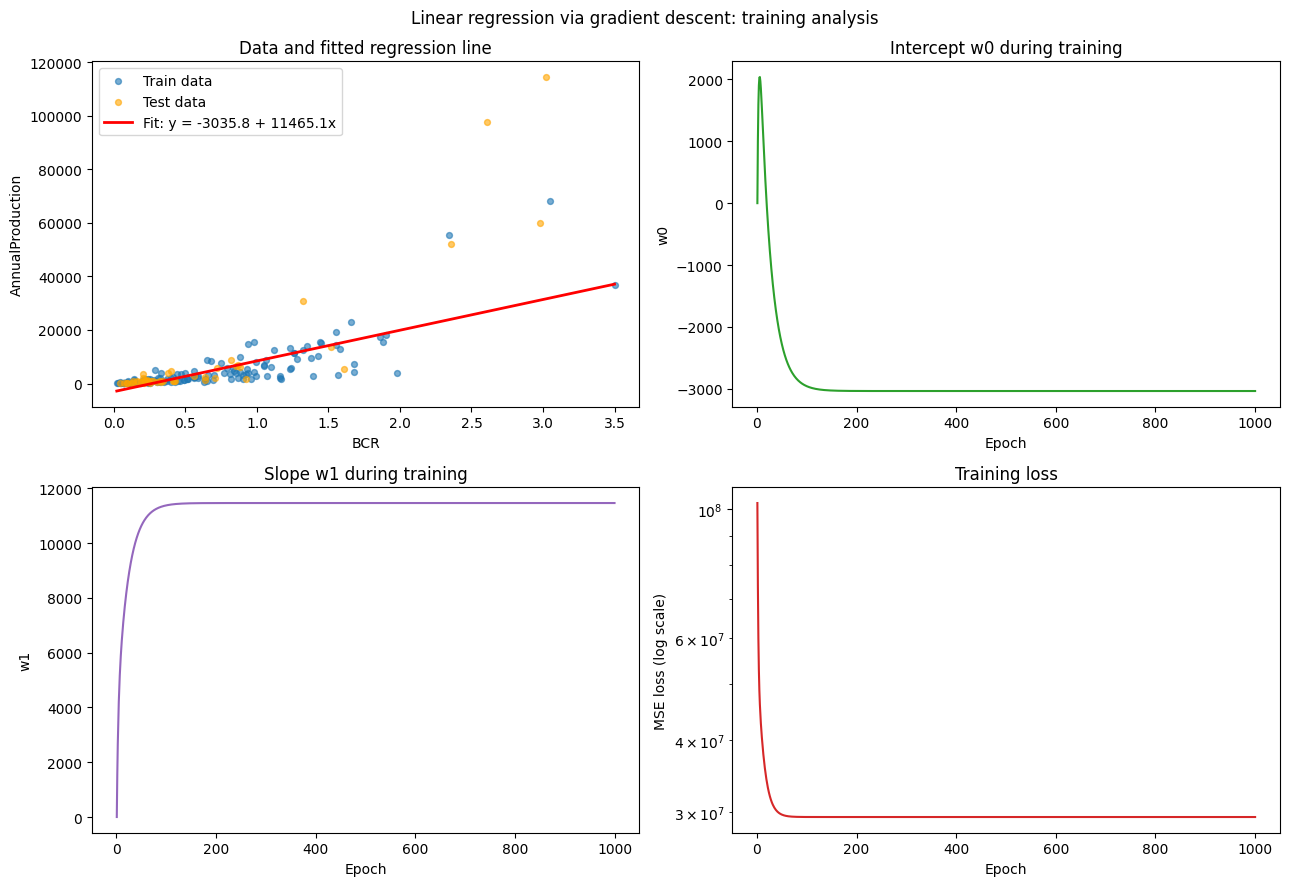

In [19]:
fig = model.analysis_plot()